# Regularisasi: Ridge, Lasso, Elastic Net, dan Gradient Descent

Course 2: Supervised Learning

Regularisasi menambahkan penalti pada besar koefisien supaya model tidak terlalu rumit dan tidak overfitting. Notebook ini terdiri dari dua bagian:

- Bagian A: demo kecil pada data sinus yang berisik, untuk melihat efek regularisasi secara visual
- Bagian B: harga rumah Ames, dipakai untuk membandingkan regresi linear, Ridge, Lasso, Elastic Net, dan SGD

## Dataset

Ada dua dataset:

- `X_Y_Sinusoid_Data.csv`: titik data `x` dan `y` yang berasal dari fungsi sinus ditambah noise (https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/X_Y_Sinusoid_Data.csv)
- `Ames_Housing_Sales.csv`: data penjualan rumah di Ames, Iowa (https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/Ames_Housing_Sales.csv)

## 1. Import

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, RidgeCV,
                                  LassoCV, ElasticNetCV, SGDRegressor)
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore", module="sklearn")
sns.set_style("whitegrid")

# Bagian A: data sinus

### Latihan 1: baca data dan gambar fungsi aslinya

(20, 2)


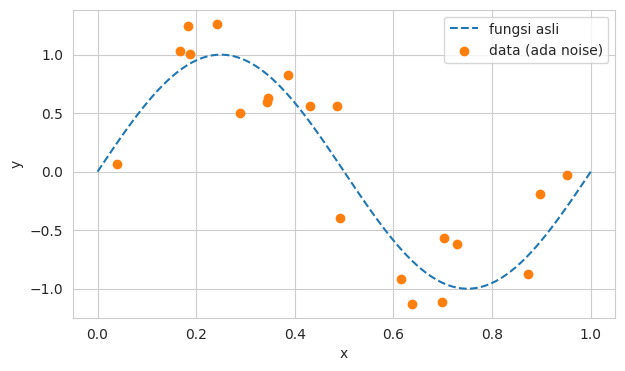

In [2]:
URL_SINUS = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/X_Y_Sinusoid_Data.csv"
sinus = pd.read_csv(URL_SINUS)
print(sinus.shape)

# fungsi aslinya: y = sin(2*pi*x), digambar dari 100 titik rapat
x_asli = np.linspace(0, 1, 100)
y_asli = np.sin(2 * np.pi * x_asli)

plt.figure(figsize=(7, 4))
plt.plot(x_asli, y_asli, "--", label="fungsi asli")
plt.scatter(sinus["x"], sinus["y"], color="C1", label="data (ada noise)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

### Latihan 2: regresi linear dengan polinomial derajat 20

Jumlah datanya sedikit, sementara fitur polinomial derajat 20 sangat banyak. Ini sengaja dibuat berlebihan untuk memancing overfitting.

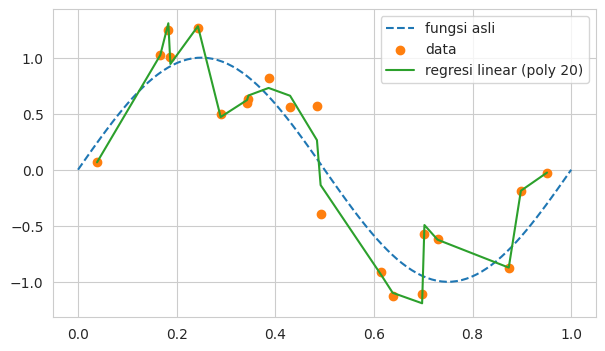

In [3]:
X_s = sinus[["x"]]
y_s = sinus["y"]

pf20 = PolynomialFeatures(degree=20)
X_s_poly = pf20.fit_transform(X_s)

lr_s = LinearRegression().fit(X_s_poly, y_s)
pred_lr = lr_s.predict(X_s_poly)

# prediksi digambar sebagai kurva halus supaya jelas bentuknya
urut = np.argsort(sinus["x"].values)
plt.figure(figsize=(7, 4))
plt.plot(x_asli, y_asli, "--", label="fungsi asli")
plt.scatter(sinus["x"], sinus["y"], color="C1", label="data")
plt.plot(sinus["x"].values[urut], pred_lr[urut], "C2-", label="regresi linear (poly 20)")
plt.legend()
plt.show()

### Latihan 3: tambahkan Ridge dan Lasso

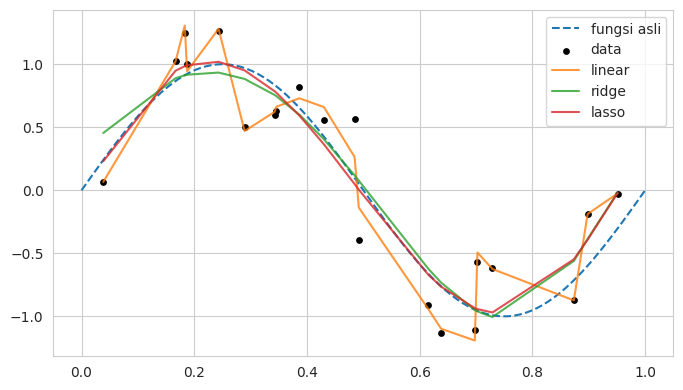

In [4]:
ridge_s = Ridge(alpha=0.001).fit(X_s_poly, y_s)
lasso_s = Lasso(alpha=0.0001, max_iter=100000).fit(X_s_poly, y_s)

plt.figure(figsize=(8, 4.5))
plt.plot(x_asli, y_asli, "--", label="fungsi asli")
plt.scatter(sinus["x"], sinus["y"], color="k", s=15, label="data")
for nama, model in [("linear", lr_s), ("ridge", ridge_s), ("lasso", lasso_s)]:
    plt.plot(sinus["x"].values[urut], model.predict(X_s_poly)[urut], label=nama, alpha=0.8)
plt.legend()
plt.show()

In [5]:
koef = pd.DataFrame({
    "linear": lr_s.coef_,
    "ridge": ridge_s.coef_,
    "lasso": lasso_s.coef_,
}).abs()

koef.describe().loc[["mean", "max"]]

,linear,ridge,lasso
mean,2.427786e+11,2.169397,2.665181
max,9.201049e+11,12.429635,25.359652


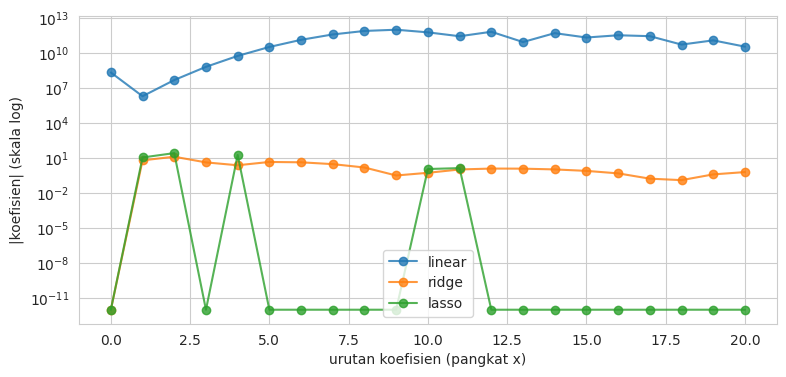

In [6]:
# skala log karena besar koefisien linear dan regularisasi beda belasan orde
plt.figure(figsize=(9, 4))
for nama in koef.columns:
    plt.semilogy(koef[nama] + 1e-12, "o-", label=nama, alpha=0.8)
plt.xlabel("urutan koefisien (pangkat x)")
plt.ylabel("|koefisien| (skala log)")
plt.legend()
plt.show()

Koefisien regresi linear biasa bisa sangat besar karena modelnya berusaha mengejar setiap titik, termasuk noise. Ridge dan Lasso menahan koefisien tetap kecil, dan hasilnya kurva prediksi lebih halus dan lebih dekat ke fungsi asli. Itulah peran regularisasi: mengorbankan sedikit ketepatan di data latih untuk model yang lebih stabil.

# Bagian B: harga rumah Ames

### Latihan 4: siapkan data

Langkahnya: baca data, one-hot encode kolom kategorikal, bagi menjadi train dan test, lalu transformasi log pada fitur float yang miring (skewness > 0.75). `SalePrice` sebagai target tidak ditransformasi. Skewness dihitung dari data train saja, lalu kolom yang sama ditransformasi di train dan test.

In [7]:
URL_AMES = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/Ames_Housing_Sales.csv"
ames = pd.read_csv(URL_AMES)
ames = pd.get_dummies(ames, drop_first=True, dtype=int)
print(ames.shape)

train, test = train_test_split(ames, test_size=0.3, random_state=42)
train, test = train.copy(), test.copy()

(1379, 241)


19 kolom ditransformasi log1p


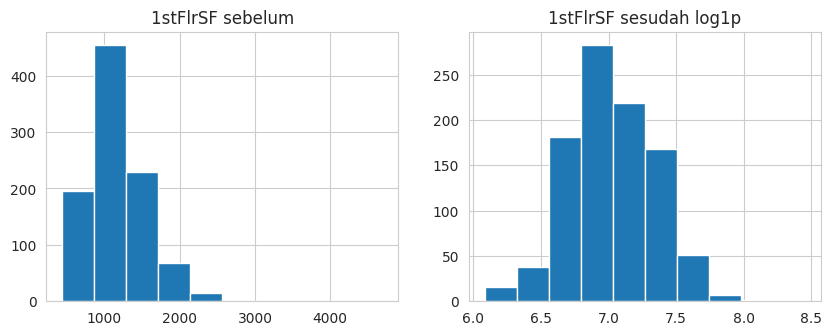

In [8]:
kolom_float = ames.select_dtypes("float").columns.drop("SalePrice")
skew = train[kolom_float].skew()
kolom_miring = skew[skew.abs() > 0.75].index

print(len(kolom_miring), "kolom ditransformasi log1p")

# contoh efeknya pada satu kolom
contoh = kolom_miring[0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
train[contoh].hist(ax=a1)
np.log1p(train[contoh]).hist(ax=a2)
a1.set_title(f"{contoh} sebelum")
a2.set_title(f"{contoh} sesudah log1p")
plt.show()

In [9]:
train[kolom_miring] = np.log1p(train[kolom_miring])
test[kolom_miring] = np.log1p(test[kolom_miring])

fitur = [c for c in train.columns if c != "SalePrice"]
X_train, y_train = train[fitur], train["SalePrice"]
X_test, y_test = test[fitur], test["SalePrice"]
print(X_train.shape, X_test.shape)

(965, 240) (414, 240)


### Latihan 5: fungsi RMSE dan model dasar

In [10]:
def rmse(y_benar, y_prediksi):
    return np.sqrt(mean_squared_error(y_benar, y_prediksi))

linear = LinearRegression().fit(X_train, y_train)
rmse_linear = rmse(y_test, linear.predict(X_test))
print("RMSE regresi linear:", round(rmse_linear, 2))

RMSE regresi linear: 42033.49


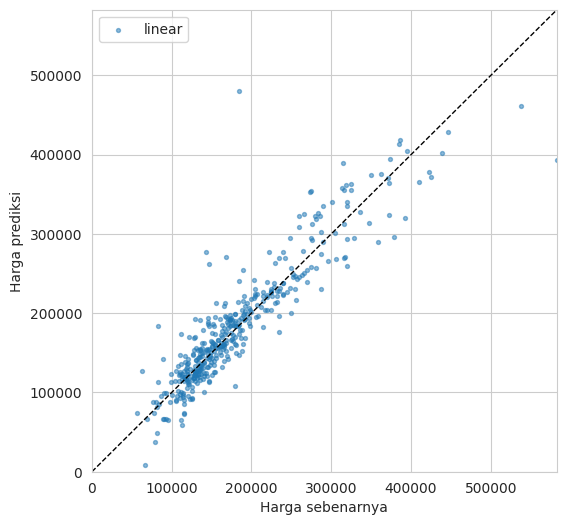

In [11]:
def plot_prediksi(daftar_model):
    fig, ax = plt.subplots(figsize=(6, 6))
    for nama, model in daftar_model.items():
        ax.scatter(y_test, model.predict(X_test), s=8, alpha=0.5, label=nama)
    batas = [0, y_test.max()]
    ax.plot(batas, batas, "k--", lw=1)
    ax.set(xlabel="Harga sebenarnya", ylabel="Harga prediksi", xlim=batas, ylim=batas)
    ax.legend()
    plt.show()

plot_prediksi({"linear": linear})

### Latihan 6: Ridge

Ridge memakai penalti L2 (kuadrat koefisien) yang mengecilkan koefisien tapi hampir tidak pernah membuatnya tepat nol. Pertama aku coba satu per satu nilai `alpha`, dinilai dengan cross validation di data train (bukan data test).

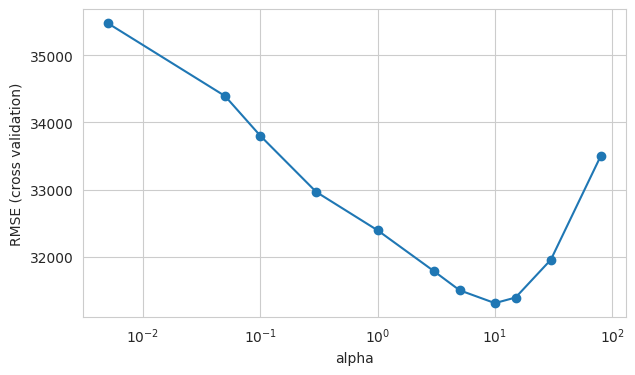

alpha terbaik dari loop: 10


In [12]:
alphas_ridge = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

rmse_cv = []
for a in alphas_ridge:
    skor = cross_val_score(Ridge(alpha=a), X_train, y_train, cv=4,
                           scoring="neg_root_mean_squared_error")
    rmse_cv.append(-skor.mean())

plt.figure(figsize=(7, 4))
plt.semilogx(alphas_ridge, rmse_cv, "-o")
plt.xlabel("alpha")
plt.ylabel("RMSE (cross validation)")
plt.show()

print("alpha terbaik dari loop:", alphas_ridge[int(np.argmin(rmse_cv))])

Cara yang lebih ringkas adalah `RidgeCV`, yang melakukan pencarian alpha itu sekaligus:

In [13]:
ridge_cv = RidgeCV(alphas=alphas_ridge, cv=4).fit(X_train, y_train)
rmse_ridge = rmse(y_test, ridge_cv.predict(X_test))
print("alpha terpilih:", ridge_cv.alpha_, "| RMSE test:", round(rmse_ridge, 2))

alpha terpilih: 10.0 | RMSE test: 32022.03


### Latihan 7: Lasso dan Elastic Net

Lasso memakai penalti L1 (nilai absolut koefisien) yang bisa menjadikan sebagian koefisien tepat nol, jadi sekaligus berfungsi sebagai seleksi fitur. Elastic Net menggabungkan penalti L1 dan L2, dikendalikan oleh `l1_ratio`.

In [14]:
alphas_kecil = np.array([1e-5, 5e-5, 1e-4, 5e-4])

lasso_cv = LassoCV(alphas=alphas_kecil, max_iter=int(5e4), cv=3).fit(X_train, y_train)
rmse_lasso = rmse(y_test, lasso_cv.predict(X_test))

print("alpha terpilih:", lasso_cv.alpha_, "| RMSE test:", round(rmse_lasso, 2))
print(f"koefisien tidak nol: {np.count_nonzero(lasso_cv.coef_)} dari {len(lasso_cv.coef_)}")

alpha terpilih: 0.0005 | RMSE test: 46069.64
koefisien tidak nol: 230 dari 240


In [ ]:
rasio = np.linspace(0.1, 0.9, 9)
enet_cv = ElasticNetCV(alphas=alphas_kecil, l1_ratio=rasio, max_iter=int(1e4), cv=3).fit(X_train, y_train)
rmse_enet = rmse(y_test, enet_cv.predict(X_test))

print("alpha:", enet_cv.alpha_, "| l1_ratio:", enet_cv.l1_ratio_, "| RMSE test:", round(rmse_enet, 2))

In [ ]:
tabel = pd.DataFrame({"RMSE": [rmse_linear, rmse_ridge, rmse_lasso, rmse_enet]},
                     index=["Linear", "Ridge", "Lasso", "ElasticNet"])
tabel.round(2)

In [ ]:
plot_prediksi({"Ridge": ridge_cv, "Lasso": lasso_cv, "ElasticNet": enet_cv})

### Latihan 8: Stochastic Gradient Descent (SGD)

SGD mencari koefisien dengan memperbarui bobot sedikit demi sedikit berdasarkan gradien, bukan dengan rumus langsung. Metode ini sangat sensitif terhadap skala fitur dan besarnya learning rate: kalau fitur belum di-scale atau learning rate terlalu besar, prediksi bisa meledak (diverge). Kalau hasilnya tidak terhingga atau NaN, aku catat sebagai NaN di tabel.

Aku pakai parameter yang didapat dari cross validation tadi, dengan pasangan penalti yang benar: Ridge = `l2`, Lasso = `l1`.

In [ ]:
def rmse_aman(y_benar, y_prediksi):
    if not np.isfinite(y_prediksi).all():
        return np.nan
    return rmse(y_benar, y_prediksi)

param_sgd = {
    "Linear": dict(penalty=None),
    "Ridge": dict(penalty="l2", alpha=ridge_cv.alpha_),
    "Lasso": dict(penalty="l1", alpha=lasso_cv.alpha_),
    "ElasticNet": dict(penalty="elasticnet", alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_),
}

def jalankan_sgd(Xa, Xb, **ekstra):
    hasil = {}
    for nama, p in param_sgd.items():
        sgd = SGDRegressor(random_state=0, **ekstra, **p).fit(Xa, y_train)
        hasil[nama] = rmse_aman(y_test, sgd.predict(Xb))
    return hasil

tabel["SGD (tanpa scaling)"] = pd.Series(jalankan_sgd(X_train, X_test))
tabel

Error SGD tanpa scaling sangat besar atau bahkan NaN, tandanya algoritmanya diverge. Salah satu cara menanganinya adalah learning rate awal (`eta0`) dikecilkan:

In [ ]:
tabel["SGD (eta0=1e-7)"] = pd.Series(jalankan_sgd(X_train, X_test, eta0=1e-7))
tabel

Cara lain yang lebih mendasar adalah men-scale fitur. Scaler di-`fit` hanya pada data train:

In [ ]:
scaler = MinMaxScaler()
Xtr_s = scaler.fit_transform(X_train)
Xte_s = scaler.transform(X_test)

tabel["SGD (MinMax scaling)"] = pd.Series(jalankan_sgd(Xtr_s, Xte_s))
tabel.round(2)

Kesimpulan bagian ini: untuk SGD, scaling fitur hampir wajib. Setelah di-scale, errornya turun ke kisaran yang wajar dan mendekati hasil model yang dihitung langsung (Ridge, Lasso, Elastic Net).